In [13]:
#Fichiers Export GeodAir : FOND et 2021-2025 (1er janvier) uniquement -
#! pip install glob
import glob
import pandas as pd

list_fich = sorted(glob.glob("../data/raw/Export_*.csv"))  
print(len(list_fich), "fichiers trouvés")

pollut = []
for f in list_fich:
    temp = pd.read_csv(f, sep=";")                   
    pollut.append(temp)

# empilement vertical des tables issues des exports réalisés à l'identique
ref = pollut[0].columns
problemes = [f for f, t in zip(list_fich, pollut) if not t.columns.equals(ref)]
if problemes:
    raise ValueError(f"PROBLEME de colonnes différentes, fichiers: {problemes}")
df_pollut = pd.concat(pollut, ignore_index=True)

n_init = len(df_pollut)
df_pollut = df_pollut[df_pollut["type d'influence"]=="Fond"]
n_fond = len(df_pollut) 
# on garde uniquement les mesures valides et positives, sans doublons
df_pollut = df_pollut[(df_pollut["validité"] != -1) & (df_pollut["valeur"] >= 0)]
df_pollut=df_pollut.drop_duplicates()
n_sans_dup= len(df_pollut) 
print(n_init, "mesures initiales")
print(n_fond, "mesures 'Fond' seulement")
print(n_sans_dup, "mesures >=0 et sans doublons")

27 fichiers trouvés
1875851 mesures initiales
1821919 mesures 'Fond' seulement
1677280 mesures >=0 et sans doublons


In [14]:
 #RATTACHEMENT GÉOGRAPHIQUE
 #station ──(lat, lon)──► code_dept

import requests
import json
import os

METRO_DEPTS = (
    {f"{i:02d}" for i in range(1, 20)}
    | {'2A', '2B'}
    | {f"{i:02d}" for i in range(21, 96)}
)

def get_departement(lat, lon):
    url = f"https://geo.api.gouv.fr/communes?lat={lat}&lon={lon}&fields=departement"
    r = requests.get(url)
    if r.ok and r.json():
        code = r.json()[0]['departement']['code']
        return code if code in METRO_DEPTS else None
    return None

# Chargement du cache existant
if os.path.exists('sites_dept.json'):
    with open('sites_dept.json') as f:
        resultats = json.load(f)
else:
    resultats = {}

sites = df_pollut[['code site', 'Latitude', 'Longitude']].drop_duplicates('code site').reset_index(drop=True)
nouveaux = sites[~sites['code site'].isin(resultats)]

for k, (_, row) in enumerate(nouveaux.iterrows()):
    if k % 10 == 0:
        print(f"{k}/{len(nouveaux)}")
    resultats[row['code site']] = get_departement(row['Latitude'], row['Longitude'])

# Sauvegarde du cache
with open('sites_dept.json', 'w') as f:
    json.dump(resultats, f)

sites['code_dept'] = sites['code site'].map(resultats)
df_pollut = df_pollut.merge(sites[['code site', 'code_dept']], on='code site', how='left')

In [15]:
print(sites["code_dept"].isna().sum(), "stations sans département")
print(sites[sites["code_dept"].isna()])            # lesquelles ?
print(sites["code_dept"].nunique(), "départements couverts")

#Correction manuelle d'un raté dans l'attribution d'une station...
df_pollut.loc[df_pollut["code site"] == "FR06001", "code_dept"] = "59"
print(df_pollut["code_dept"].isna().sum())

df_pollut.to_csv("../data/processed/Pollution_moy_journaliere_FOND.csv", index=False)

1 stations sans département
    code site  Latitude  Longitude code_dept
187   FR06001  50.35853    3.50804       NaN
90 départements couverts
0


In [2]:
#On repart d'une lecture fraiche, avec un format str imposé pour code_dept
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_pollut =[]
df=pd.read_csv("../data/processed/Pollution_moy_journaliere_FOND.csv",dtype={"code_dept": str})
display(df.head())

,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,Latitude,Longitude,code_dept
0,2021/01/01 00:00:00,2021/01/01 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,1.758333,µg-m3,100.0,100,100.0,R,1,46.652668,3.600667,03
1,2021/01/02 00:00:00,2021/01/02 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,1.979167,µg-m3,100.0,100,100.0,A,1,46.652668,3.600667,03
2,2021/01/03 00:00:00,2021/01/03 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,3.650000,µg-m3,100.0,100,100.0,A,1,46.652668,3.600667,03
3,2021/01/04 00:00:00,2021/01/04 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,3.675000,µg-m3,100.0,100,100.0,R,1,46.652668,3.600667,03
4,2021/01/05 00:00:00,2021/01/05 23:59:59,ATMO AUVERGNE-RHÔNE-ALPES,FR84ZRE01,ZR AUVERGNE-RHONE-ALPES,FR07022,Paray le Fresil,Rurale régionale,NOX as NO2,Fond,...,4.229167,µg-m3,100.0,100,100.0,A,1,46.652668,3.600667,03


In [3]:
#AGRÉGATION HEBDOMADAIRE
##Contrôles initiaux : id_jour unique, vérification des unités de mesure des polluants

df["id_jour"] = pd.to_datetime(df["Date de fin"]).dt.normalize()
print(pd.crosstab(df["Polluant"], df["unité de mesure"]))
#Recherche de doublons avec unités de mesure différentes
cles = ["code site", "Date de début", "Polluant"]
print(df.duplicated(subset=cles).sum(), "mesures en double station × jour × polluant")

unité de mesure  P.cm3  mg-m3   µg-m3  µg/m3
Polluant                                    
C6H6                 0      0     247    283
CO                   0   4890       0      0
Chl in PM1           0      0    9061    876
NH4 in PM1           0      0    9205    874
NO2                  0      0  340733   2569
NO3 in PM1           0      0    9506    875
NOX as NO2           0      0  311846    427
Nb PM 10nm        6125      0       0      0
O3                   0      0  409390      0
Org in PM1           0      0    9504    874
PM10                 0      0  293756   8921
PM2.5                0      0  207807   6664
SO2                  0      0   32466      0
SO4 in PM1           0      0    9506    875
0 mesures en double station × jour × polluant


In [4]:
#AGRÉGATION HEBDOMADAIRE
##Moyenne journalière par polluant

moy_jour = df.groupby(["code_dept", "id_jour", "Polluant"])["valeur"].mean()
moy_jour = moy_jour.reset_index()                     
print(moy_jour.head())

  code_dept    id_jour Polluant  valeur
0        01 2021-01-01      NO2    4.55
1        01 2021-01-01       O3   43.00
2        01 2021-01-01     PM10    7.50
3        01 2021-01-01    PM2.5    9.90
4        01 2021-01-02      NO2    6.05


In [5]:
#AGRÉGATION HEBDOMADAIRE

iso = df["id_jour"].dt.isocalendar()
df["date_semaine"] = iso["year"].astype(str) + "-S" + iso["week"].astype(str).str.zfill(2)
print(df[["id_jour", "date_semaine"]].head())

##Moyenne hebdomadaire par polluant
moy_sem = df.groupby(["code_dept", "date_semaine", "Polluant"])["valeur"].mean()
moy_sem = moy_sem.reset_index().rename(columns={"valeur": "moyenne"})
print(moy_sem.head())

##Moyenne hebdomadaire par polluant
max_sem = df.groupby(["code_dept", "date_semaine", "Polluant"])["valeur"].max()
max_sem = max_sem.reset_index().rename(columns={"valeur": "maximum"})
print(max_sem.head())

##Nombre de mesures hebdomadaire par polluant
n_sem = df.groupby(["code_dept", "date_semaine", "Polluant"])["valeur"].count()
n_sem = n_sem.reset_index().rename(columns={"valeur": "n_mesures"})
print(n_sem.head())

##Fusion des trois tables
hebdo = moy_sem.merge(max_sem, on=["code_dept", "date_semaine", "Polluant"])
hebdo = hebdo.merge(n_sem,     on=["code_dept", "date_semaine", "Polluant"])
print(hebdo.head())

##Nombre de stations distinctes par département, semaine et polluant
nst_sem = df.groupby(["code_dept", "date_semaine", "Polluant"])["code site"].nunique()
nst_sem = nst_sem.reset_index().rename(columns={"code site": "nb_stations"})
hebdo = hebdo.merge(nst_sem, on=["code_dept", "date_semaine", "Polluant"])
print(hebdo.head())
print(hebdo.shape)

     id_jour date_semaine
0 2021-01-01     2020-S53
1 2021-01-02     2020-S53
2 2021-01-03     2020-S53
3 2021-01-04     2021-S01
4 2021-01-05     2021-S01
  code_dept date_semaine Polluant    moyenne
0        01     2020-S53      NO2   6.350000
1        01     2020-S53       O3  36.000000
2        01     2020-S53     PM10  11.166667
3        01     2020-S53    PM2.5  13.966667
4        01     2021-S01      NO2  16.272727
  code_dept date_semaine Polluant  maximum
0        01     2020-S53      NO2      8.7
1        01     2020-S53       O3     44.0
2        01     2020-S53     PM10     18.0
3        01     2020-S53    PM2.5     17.0
4        01     2021-S01      NO2     21.0
  code_dept date_semaine Polluant  n_mesures
0        01     2020-S53      NO2          6
1        01     2020-S53       O3          6
2        01     2020-S53     PM10          6
3        01     2020-S53    PM2.5          3
4        01     2021-S01      NO2         11
  code_dept date_semaine Polluant    moyenne  

208 semaines


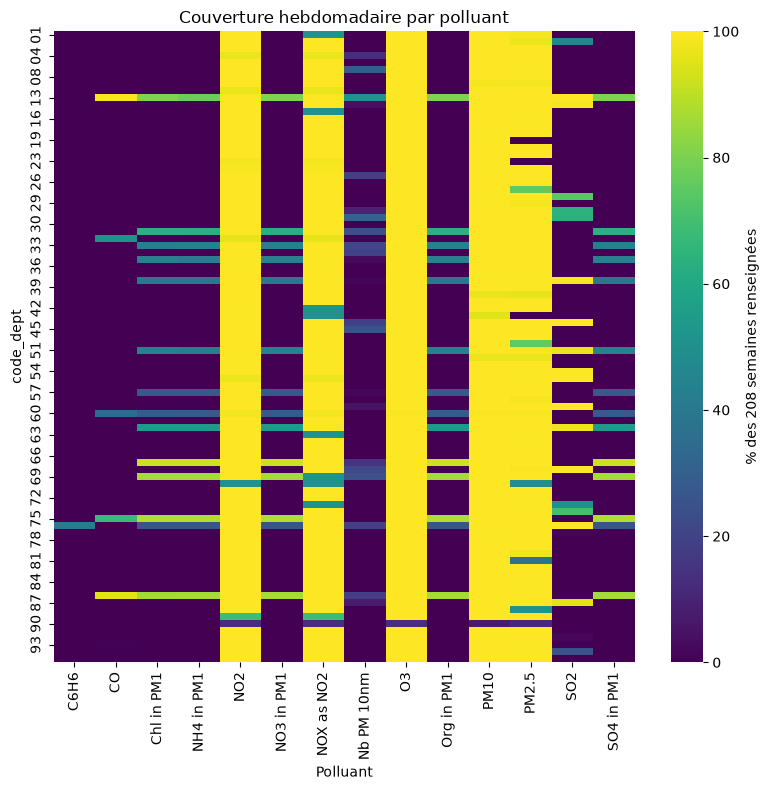

Polluant
NO2           90
NOX as NO2    90
O3            90
PM10          90
PM2.5         87
SO2           19
Nb PM 10nm    19
Chl in PM1    14
NO3 in PM1    14
NH4 in PM1    14
Org in PM1    14
SO4 in PM1    14
CO             5
C6H6           1
Name: valeur, dtype: int64
DECISION = couverture trop faible pour CO & C6H6 - tous les autres polluants sont conservés.


In [6]:
import seaborn as sns

hebdo = hebdo[(hebdo["date_semaine"] >= "2021-S01") & (hebdo["date_semaine"] <= "2024-S52")]
#polluants = df['Polluant'].unique()
#hebdo = hebdo[hebdo["Polluant"].isin(polluants)]
print(hebdo["date_semaine"].nunique(), "semaines")        # attendu : 208

## Graphique couverture hébdomadaire par département et par polluant
couv = hebdo.groupby(["code_dept", "Polluant"])["date_semaine"].nunique()
couv = couv.unstack(fill_value=0)                          # départements en lignes, polluants en colonnes
couv_pct = 100 * couv / 208                                # en % des 208 semaines
#print(couv_pct.round(0))

plt.figure(figsize=(8, 8))
sns.heatmap(couv_pct, cmap="viridis", vmin=0, vmax=100,
            cbar_kws={"label": "% des 208 semaines renseignées"})
plt.title("Couverture hebdomadaire par polluant")
plt.tight_layout()
plt.show()

##Nb de départements avec un minimum de ~12 mesures par an
est_mesure = df.groupby(["Polluant", "code_dept"])["valeur"].count()> 50
print(est_mesure.groupby("Polluant").sum().sort_values(ascending=False))
print("DECISION = couverture trop faible pour CO & C6H6 - tous les autres polluants sont conservés.")

In [19]:
polluants = ["NO2", "O3", "PM10","PM2.5", "SO2", "Nb PM 10nm","Chl in PM1","NO3 in PM1", "NH4 in PM1", "Org in PM1", "SO4 in PM1"]
toutes_dates = sorted(hebdo['date_semaine'].unique())

hebdo_piv = (hebdo[hebdo["Polluant"].isin(polluants)]
              .pivot_table(index=["date_semaine", "code_dept"],
                           columns="Polluant",
                           values="moyenne")       # moyenne hebdomadaire départementale
              .reset_index())
hebdo_piv.columns.name = None                     # retire le titre "Polluant" au-dessus des colonnes
hebdo_piv = hebdo_piv.sort_values(["date_semaine", "code_dept"]).reset_index(drop=True)

display(hebdo_piv.head())
print(hebdo_piv.shape)
print(hebdo_piv.isna().sum())   

,date_semaine,code_dept,Chl in PM1,NH4 in PM1,NO2,NO3 in PM1,Nb PM 10nm,O3,Org in PM1,PM10,PM2.5,SO2,SO4 in PM1
0,2021-S01,01,NaN,NaN,16.272727,NaN,NaN,20.909091,NaN,19.363636,20.750000,NaN,NaN
1,2021-S01,02,NaN,NaN,25.000000,NaN,NaN,12.714286,NaN,21.714286,NaN,NaN,NaN
2,2021-S01,03,NaN,NaN,14.596429,NaN,NaN,20.892857,NaN,19.285714,17.285714,NaN,NaN
3,2021-S01,04,NaN,NaN,16.428571,NaN,NaN,44.461538,NaN,14.285714,12.635714,NaN,NaN
4,2021-S01,05,NaN,NaN,27.000000,NaN,NaN,59.214286,NaN,19.571429,18.285714,NaN,NaN


(18537, 13)
date_semaine        0
code_dept           0
Chl in PM1      16866
NH4 in PM1      16878
NO2               208
NO3 in PM1      16863
Nb PM 10nm      17741
O3                  1
Org in PM1      16863
PM10               46
PM2.5            1120
SO2             15244
SO4 in PM1      16861
dtype: int64


In [20]:
#!pip install geopandas
import geopandas as gpd

geo = gpd.read_file("https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson").set_index('code')

voisins = {}
for dept in geo.index:
    touches = geo[geo.geometry.touches(geo.loc[dept, 'geometry'])].index.tolist()
    voisins[dept] = touches

# Ajout manuel des liens Corse <-> continent
for dept_corse in ['2A', '2B']:
    for dept_continent in ['06', '83']:
        if dept_continent not in voisins[dept_corse]:
            voisins[dept_corse].append(dept_continent)
        if dept_corse not in voisins[dept_continent]:
            voisins[dept_continent].append(dept_corse)

df_voisins = pd.DataFrame([
    {'code_dept': dept, 'voisins': voisins[dept]}
    for dept in voisins
]).sort_values('code_dept').reset_index(drop=True)

#df_voisins.to_csv('Voisins.csv')

In [22]:
week = toutes_dates[0]
pol = polluants[10]

tous_depts = [f"{i:02d}" for i in range(1, 96) if i != 20] + ['2A', '2B']
s_full = pd.Series(np.nan, index=tous_depts, name=pol)

s_source = hebdo_piv[hebdo_piv['date_semaine'] == week].set_index('code_dept')[pol]
s_full.update(s_source)
s = s_full.copy()
n = 0

print(f"Avant toute passe — Départements manquants : {s.isna().sum()}")
print(f"Départements remplis : {s.notna().sum()}")
print(s[s.notna()].index.tolist())

Avant toute passe — Départements manquants : 89
Départements remplis : 7
['13', '57', '60', '67', '69', '75', '86']


Passe 1 — manquants : 88 — remplis : 8


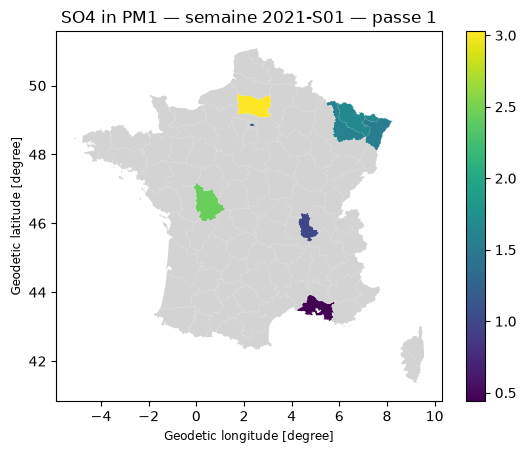

Passe 2 — manquants : 87 — remplis : 9


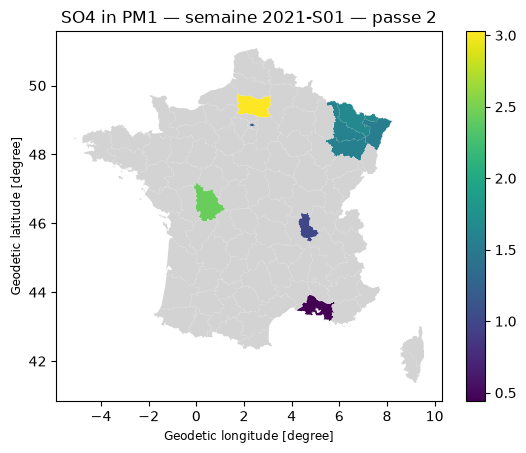

Passe 3 — manquants : 85 — remplis : 11


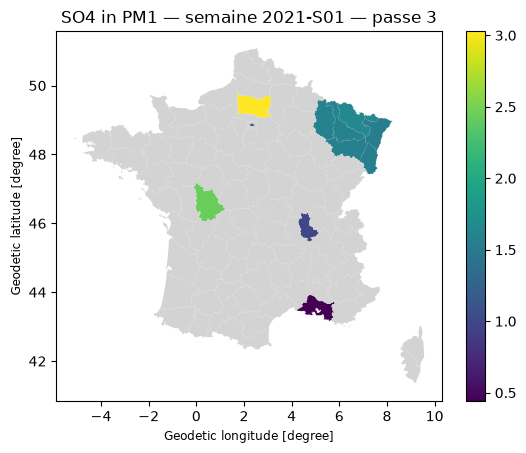

Passe 4 — manquants : 83 — remplis : 13


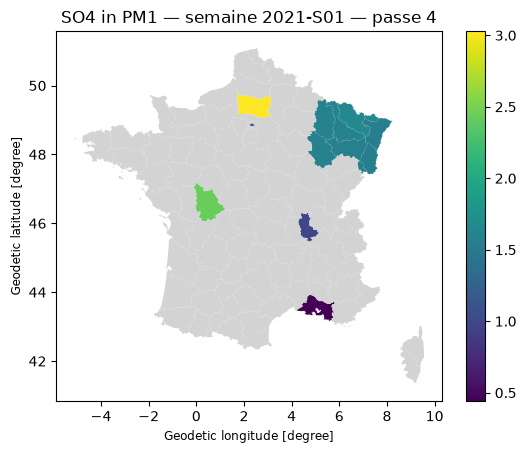

Passe 5 — manquants : 81 — remplis : 15


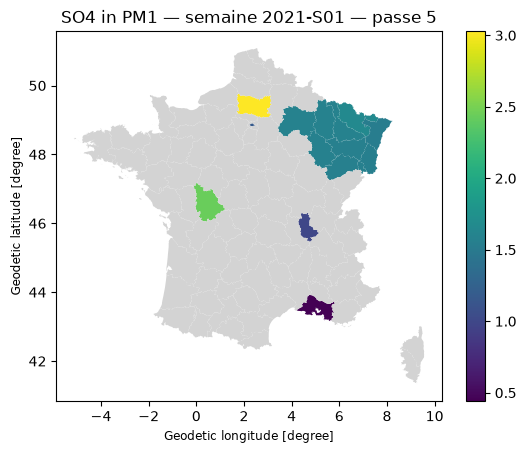

Passe 6 — manquants : 75 — remplis : 21


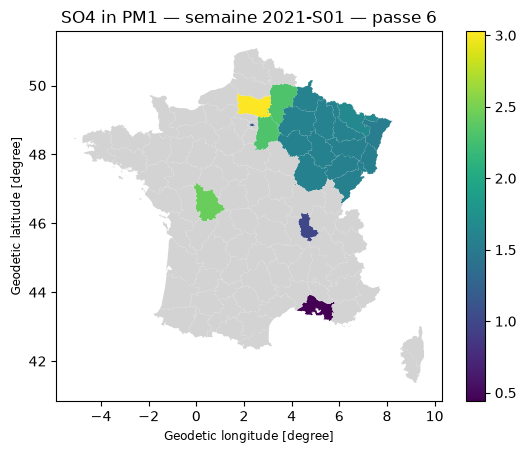

Passe 7 — manquants : 68 — remplis : 28


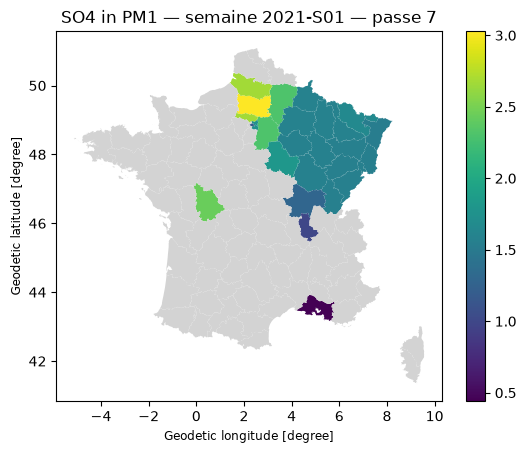

Passe 8 — manquants : 59 — remplis : 37


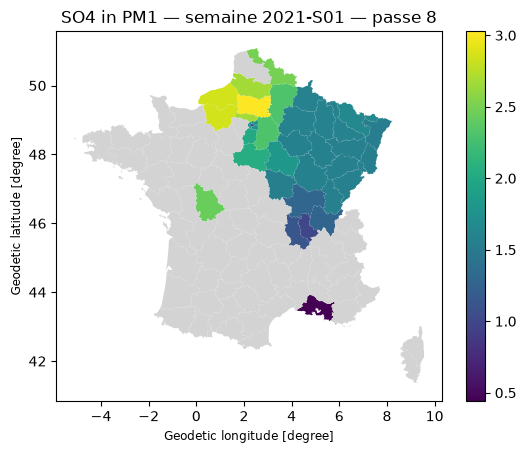

Passe 9 — manquants : 53 — remplis : 43


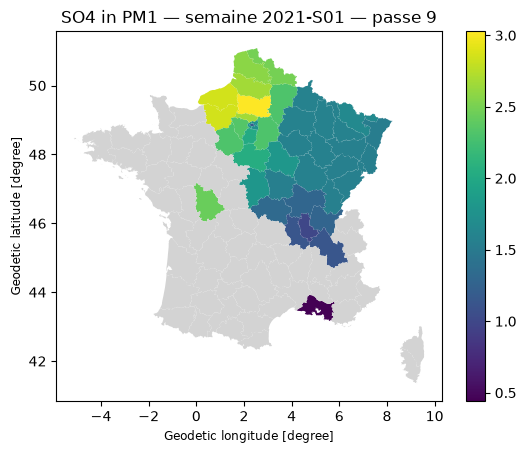

Passe 10 — manquants : 46 — remplis : 50


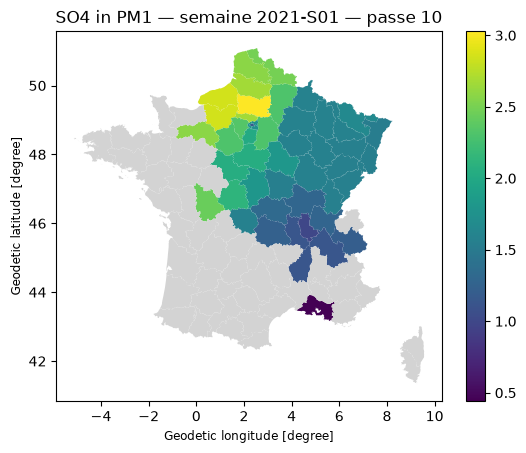

Passe 11 — manquants : 35 — remplis : 61


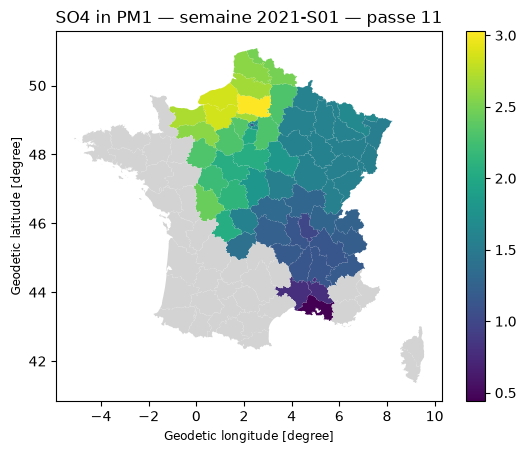

Passe 12 — manquants : 26 — remplis : 70


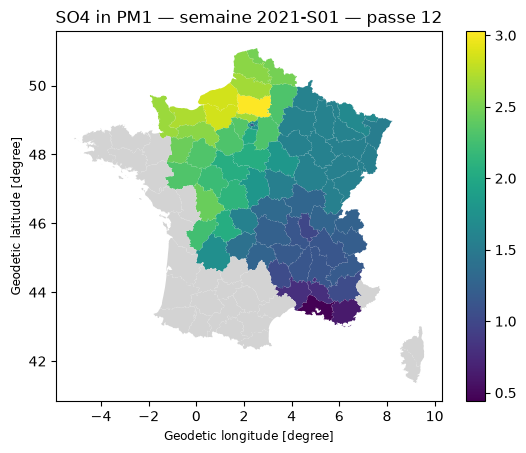

Passe 13 — manquants : 20 — remplis : 76


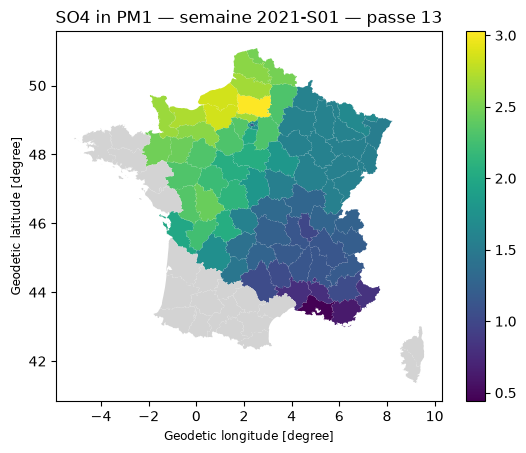

Passe 14 — manquants : 12 — remplis : 84


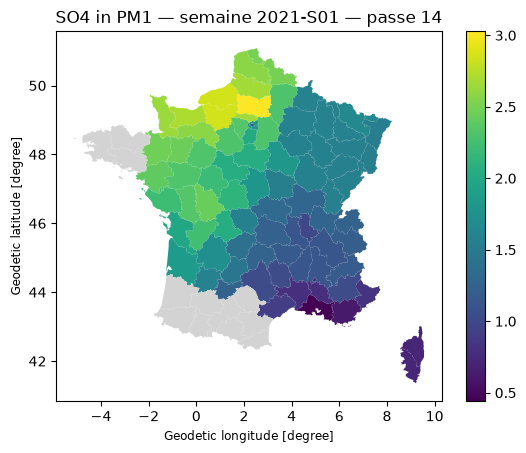

Passe 15 — manquants : 8 — remplis : 88


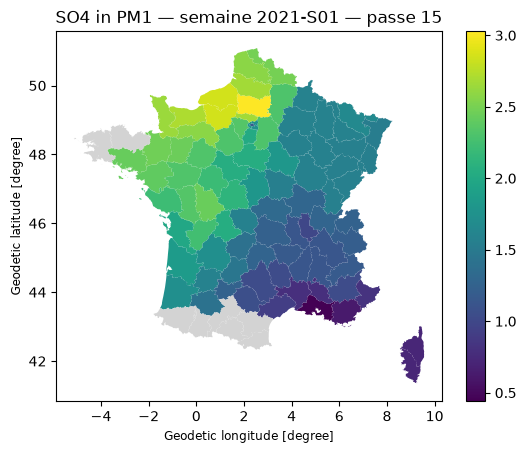

Passe 16 — manquants : 4 — remplis : 92


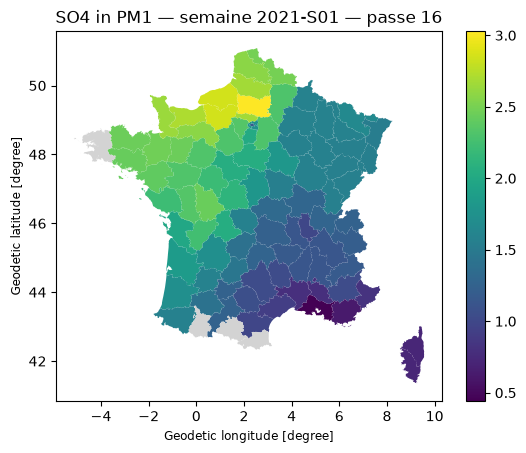

Passe 17 — manquants : 1 — remplis : 95


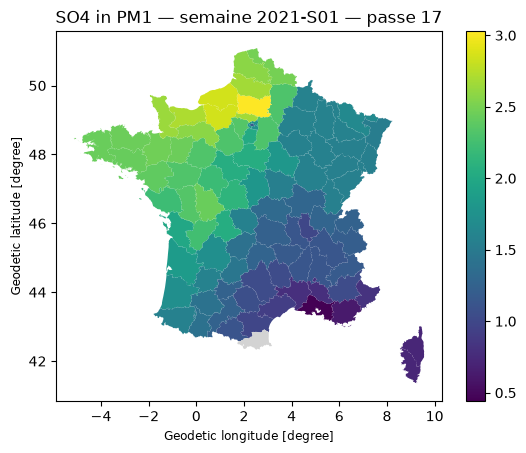

Passe 18 — manquants : 0 — remplis : 96


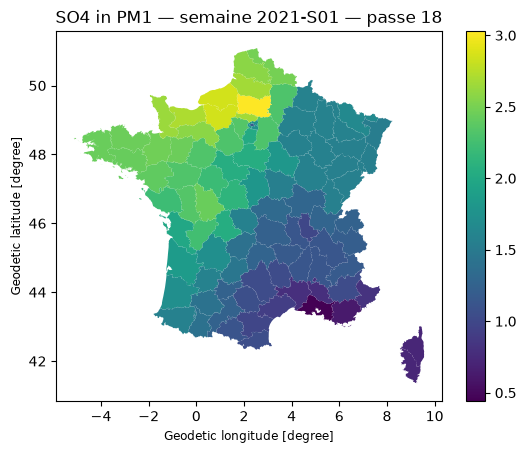

In [24]:
show = True  # passer à False pour désactiver les cartes

# Vérification initiale
if s.notna().sum() == 0:
    print("Aucune mesure disponible — arrêt du processus.")
else:
    # Phase 1 : passes avec >= 2 voisins
    while True:
        n += 1
        s_avant = s.copy()
        for dept in s_avant[s_avant.isna()].index:
            vois_values = [s_avant[v] for v in voisins.get(dept, []) if v in s_avant.index and pd.notna(s_avant[v])]
            if len(vois_values) >= 2:
                s[dept] = np.mean(vois_values)

        print(f"Passe {n} — manquants : {s.isna().sum()} — remplis : {s.notna().sum()}")

        if show:
            geo_plot = geo.copy()
            geo_plot['valeur'] = s.rename_axis('code')
            geo_plot.plot(column='valeur', legend=True, missing_kwds={'color': 'lightgrey'})
            plt.title(f"{pol} — semaine {week} — passe {n}")
            plt.show()

        if s.isna().sum() == 0:
            break
        if s.notna().sum() <= s_avant.notna().sum():  # plus de progression
            break

    # Phase 2 : passes exceptionnelles avec >= 1 voisin
    while s.isna().sum() > 0:
        n += 1
        s_avant = s.copy()
        for dept in s_avant[s_avant.isna()].index:
            vois_values = [s_avant[v] for v in voisins.get(dept, []) if v in s_avant.index and pd.notna(s_avant[v])]
            if len(vois_values) >= 1:
                s[dept] = np.mean(vois_values)

        print(f"Passe exceptionnelle {n} — manquants : {s.isna().sum()} — remplis : {s.notna().sum()}")

        if show:
            geo_plot = geo.copy()
            geo_plot['valeur'] = s.rename_axis('code')
            geo_plot.plot(column='valeur', legend=True, missing_kwds={'color': 'lightgrey'})
            plt.title(f"{pol} — semaine {week} — passe exceptionnelle {n}")
            plt.show()

        if s.notna().sum() <= s_avant.notna().sum():  # blocage définitif
            print("Impossible de remplir tous les départements — arrêt.")
            break

In [25]:
#!pip install tqdm
from tqdm import tqdm

def coloniser(df_temporal, polluants, toutes_semaines, voisins):
    
    tous_depts = [f"{i:02d}" for i in range(1, 96) if i != 20] + ['2A', '2B']
    
    # Squelette complet dept × date_semaine
    index = pd.MultiIndex.from_product([toutes_semaines, tous_depts], names=['date_semaine', 'code_dept'])
    df_out = pd.DataFrame(index=index).reset_index()

    for pol in polluants:
        print(f"\nPolluant : {pol}")
        df_out[pol] = np.nan
        
        for date_semaine in tqdm(toutes_semaines, desc=pol):
            s_full = pd.Series(np.nan, index=tous_depts, name=pol)
            s_source = df_temporal[df_temporal['date_semaine'] == date_semaine].set_index('code_dept')[pol]
            s_full.update(s_source)
            s = s_full.copy()
            
            if s.notna().sum() == 0:
                continue

            while True:
                s_avant = s.copy()
                for dept in s_avant[s_avant.isna()].index:
                    vois_values = [s_avant[v] for v in voisins.get(dept, []) if v in s_avant.index and pd.notna(s_avant[v])]
                    if len(vois_values) >= 2:
                        s[dept] = np.mean(vois_values)
                if s.isna().sum() == 0:
                    break
                if s.notna().sum() <= s_avant.notna().sum():
                    break

            while s.isna().sum() > 0:
                s_avant = s.copy()
                for dept in s_avant[s_avant.isna()].index:
                    vois_values = [s_avant[v] for v in voisins.get(dept, []) if v in s_avant.index and pd.notna(s_avant[v])]
                    if len(vois_values) >= 1:
                        s[dept] = np.mean(vois_values)
                if s.notna().sum() <= s_avant.notna().sum():
                    break

            df_out.loc[df_out['date_semaine'] == date_semaine, pol] = \
                df_out.loc[df_out['date_semaine'] == date_semaine, 'code_dept'].map(s).values

    return df_out

In [26]:
hebdo_colonise = coloniser(hebdo_piv, polluants, toutes_dates, voisins)
hebdo_colonise = hebdo_colonise[hebdo_colonise['date_semaine'].str[:4].isin(['2021', '2022', '2023', '2024'])]
#df_colonise = df_colonise[df_colonise['date_semaine'].str[:4].isin(['2025'])]
hebdo_colonise.to_csv('../data/final_metropole/pollution2_2021_2024.csv', index=False)


Polluant : NO2


NO2: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:02<00:00, 98.48it/s]



Polluant : O3


O3: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:02<00:00, 98.78it/s]



Polluant : PM10


...

NH4 in PM1: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:08<00:00, 24.62it/s]



Polluant : Org in PM1


Org in PM1: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:07<00:00, 27.15it/s]



Polluant : SO4 in PM1


SO4 in PM1: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:07<00:00, 26.70it/s]


In [31]:
pollut1=pd.read_csv('../data/final_metropole/pollution1_2021_2024.csv')
display(pollut1.shape)
display(pollut1.head())

pollut2=pd.read_csv('../data/final_metropole/pollution2_2021_2024.csv')
display(pollut2.shape)
display(pollut2.head())

pollut2=pollut2.drop(columns=["Nb PM 10nm"])
pollut3=pollut1.merge(pollut2,on=['date_semaine', 'code_dept'], how='left')
pollut3.to_csv('../data/final_metropole/pollution3_2021_2024.csv', index=False)

(19968, 7)

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10
0,2021-S01,01,0.326250,0.610000,0.050000,0.422500,0.002025
1,2021-S01,02,0.156000,0.725417,0.050000,0.503750,0.002756
2,2021-S01,03,0.224867,0.236667,0.063500,0.447000,0.002264
3,2021-S01,04,0.195000,0.521111,0.110417,0.421667,0.002683
4,2021-S01,05,0.293333,0.760000,0.045833,0.226667,0.001333


(19968, 13)

,date_semaine,code_dept,NO2,O3,PM10,PM2.5,SO2,Nb PM 10nm,Chl in PM1,NO3 in PM1,NH4 in PM1,Org in PM1,SO4 in PM1
0,2021-S01,01,16.272727,20.909091,19.363636,20.750000,3.569048,NaN,0.098030,4.096577,1.677753,4.961161,1.280417
1,2021-S01,02,25.000000,12.714286,21.714286,16.189023,2.750000,NaN,0.225232,4.069196,2.017634,5.589732,2.301607
2,2021-S01,03,14.596429,20.892857,19.285714,17.285714,2.091799,NaN,0.102711,4.078646,1.685140,4.963451,1.324997
3,2021-S01,04,16.428571,44.461538,14.285714,12.635714,2.649206,NaN,0.091275,3.832347,1.474710,4.584212,1.034733
4,2021-S01,05,27.000000,59.214286,19.571429,18.285714,5.228571,NaN,0.100592,4.334803,1.716992,5.017504,1.174174
